# Data Cleaning
UFC fight stats dataset — cleaning before modeling.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn regex

Note: you may need to restart the kernel to use updated packages.


## Load Data

In [2]:
import pandas as pd
import numpy as np
import regex as re
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
fights = pd.read_csv('../data/raw/ufc_event_fight_stats.csv')
fighters = pd.read_csv('../data/raw/ufc_fighters.csv')
events = pd.read_csv('../data/raw/ufc_events.csv')

print(fights.shape, fighters.shape, events.shape)

(7840, 58) (4262, 19) (711, 4)


## Initial Overview

In [4]:
# Check dtypes and non-null counts
# fights.info()

In [5]:
# Count missing values per column
# fights.isnull().sum()

In [6]:
# Quick look at a few rows
# fights.head()

## Handle Missing Values

In [7]:
# fighters.csv also has NaN for these fighters — can't use to fill in missing values.
# Strategy:
#   height    -> keep missing height rows for now so they can be used for feature engineering
#             -> drop rows (only 16 rows, height is meaningful so don't impute)
#   age       -> keep missing age rows so they can be used in for feature engineering 
#             -> will be dropped after feature engineering (163 rows)
#   ctrl_time -> fill with 0 (no control recorded = 0 seconds) 
#   no contest -> drop all no contest results (143)

#  Height: drop rows with missing height 
# before = len(fights)
# fights.dropna(subset=['f1_height_cm', 'f2_height_cm'], inplace=True)
# print(f'Dropped {before - len(fights)} rows with missing height. Remaining: {len(fights)}')

#  Age: fill with median 
# missing_age = fights['f1_age_during'].isnull().sum() + fights['f2_age_during'].isnull().sum()
# print(f'Rows with missing age (f1 or f2): {missing_age} ({fights["f1_age_during"].isnull().sum()} f1, {fights["f2_age_during"].isnull().sum()} f2)')
# fights['f1_age_during'] = fights['f1_age_during'].fillna(fights['f1_age_during'].median())
# fights['f2_age_during'] = fights['f2_age_during'].fillna(fights['f2_age_during'].median())

#  Control time: fill with 0 
fights['f1_ctrl_time'] = fights['f1_ctrl_time'].fillna(0)
fights['f2_ctrl_time'] = fights['f2_ctrl_time'].fillna(0)

#  No contest: result of 'nc' (no contest) to NaN, then dropped those rows
fights['result'] = pd.to_numeric(fights['result'], errors='coerce').astype('Int64')
before = len(fights)
fights.dropna(subset=['result'], inplace=True)
print(f'Dropped {before - len(fights)} no-contest rows. Remaining: {len(fights)}')

# Verify — should be 0
print(fights[['f1_ctrl_time','f2_ctrl_time']].isnull().sum())

Dropped 143 no-contest rows. Remaining: 7697
f1_ctrl_time    0
f2_ctrl_time    0
dtype: int64


All fields in `fights` except `age` should have no null values here.

## Data Types

In [8]:
# date columns to datetime
fighters['fighter_dob'] = pd.to_datetime(fighters['fighter_dob'])


## Target Column
`result` holds the winner's fighter_id.
Now `winner` holds 1 if f1 wins, 0 if f2 wins

In [9]:
# target variable
fights['winner'] = (fights['result'] == fights['f1_id']).astype(int)

## Handle Categorical Columns
encodes `weight class` as follows:
| Encoding | Men's | Women's |
|----------|-------|---------|
| 0 | Flyweight | Flyweight |
| 1 | Bantamweight | Strawweight |
| 2 | Featherweight | Bantamweight |
| 3 | Lightweight | Featherweight |
| 4 | Welterweight | Other |
| 5 | Middleweight | |
| 6 | Light Heavyweight | |
| 7 | Heavyweight | |
| 8 | Catch Weight | |
| 9 | Open Weight | |
| 10| Other | |

adds `is_title_bout`

In [10]:
# Check unique weight classes
# pd.set_option("display.max_rows", None)
# fights['weight_class'].value_counts()

In [11]:
is_womens = fights['weight_class'].str.contains("Women's")

# MEN'S (0-8)
mens_conditions = [
    fights['weight_class'].str.contains('Flyweight') & ~is_womens,         # 0
    fights['weight_class'].str.contains('Bantamweight') & ~is_womens,      # 1
    fights['weight_class'].str.contains('Featherweight') & ~is_womens,     # 2
    fights['weight_class'].str.contains('Lightweight') & ~is_womens,       # 3
    fights['weight_class'].str.contains('Welterweight') & ~is_womens,      # 4
    fights['weight_class'].str.contains('Middleweight') & ~is_womens,      # 5
    fights['weight_class'].str.contains('Light Heavyweight') & ~is_womens, # 6
    fights['weight_class'].str.contains('Heavyweight') & ~is_womens,       # 7
    fights['weight_class'].str.contains('Catch Weight') & ~is_womens,      # 8
    fights['weight_class'].str.contains('Open Weight') & ~is_womens,       # 9
    ~is_womens                                                             # 10 (other)
]

# WOMEN'S (0-3)
womens_conditions = [
    is_womens & fights['weight_class'].str.contains('Flyweight'),      # 0
    is_womens & fights['weight_class'].str.contains('Strawweight'),    # 1
    is_womens & fights['weight_class'].str.contains('Bantamweight'),   # 2
    is_womens & fights['weight_class'].str.contains('Featherweight'),  # 3
    is_womens                                                          # 4
]

fights['mens_class_encoded'] = np.select(mens_conditions, [0,1,2,3,4,5,6,7,8, 9, 10], default=-1)
fights['womens_class_encoded'] = np.select(womens_conditions, [0,1,2,3, 4], default=-1)

# is a title bout
fights['is_title_bout'] = fights['weight_class'].str.contains('Title')

In [12]:
fights['mens_class_encoded'].value_counts()
# fights['womens_class_encoded'].value_counts()

mens_class_encoded
 3     1317
 4     1289
 5     1024
-1      797
 2      753
 7      697
 6      681
 1      673
 0      348
 8       66
 9       45
 10       7
Name: count, dtype: int64

## 8. Check for Duplicates

In [13]:
# no duplicates
print(fights.duplicated().sum())

0


## 9. Check for Outliers
Look at numeric columns for extreme values that may be errors.

In [14]:
# Basic stats to spot outliers
d = fights.describe()
d

,f1_id,f2_id,f1_age_during,f2_age_during,f1_height_cm,f2_height_cm,f1_knockdowns,f2_knockdowns,f1_sig_strike_atts,f2_sig_strike_atts,...,f1_ground_atts,f2_ground_atts,f1_grounds,f2_grounds,f1_total_fight_time,f2_total_fight_time,result,winner,mens_class_encoded,womens_class_encoded
count,7697.000000,7697.000000,7648.000000,7569.000000,7691.000000,7686.000000,7697.000000,7697.000000,7697.000000,7697.000000,...,7697.000000,7697.000000,7697.000000,7697.000000,7697.000000,7697.000000,7697.0,7697.000000,7697.000000,7697.000000
mean,2109.059114,2106.164090,30.003530,29.643810,178.498161,178.404762,0.247239,0.182279,85.187606,79.879304,...,8.852280,5.553332,6.097311,3.785631,635.349747,635.349747,2101.894764,0.646356,3.322983,-0.788099
std,1218.691307,1215.370906,4.262274,4.063771,9.047082,8.955907,0.520937,0.458130,71.648008,69.344732,...,14.486772,11.151564,9.961661,7.877541,362.178583,362.178583,1210.110799,0.478131,2.412854,0.679690
min,4.000000,2.000000,18.000000,18.000000,152.400000,152.400000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,5.000000,5.000000,4.0,0.000000,-1.000000,-1.000000
25%,1043.000000,1037.000000,27.000000,27.000000,172.720000,172.720000,0.000000,0.000000,29.000000,25.000000,...,0.000000,0.000000,0.000000,0.000000,280.000000,280.000000,1043.0,0.000000,2.000000,-1.000000
50%,2144.000000,2121.000000,30.000000,29.000000,177.800000,177.800000,0.000000,0.000000,68.000000,62.000000,...,3.000000,1.000000,2.000000,1.000000,816.000000,816.000000,2137.0,1.000000,3.000000,-1.000000
75%,3125.000000,3146.000000,33.000000,32.000000,185.420000,185.420000,0.000000,0.000000,122.000000,117.000000,...,11.000000,6.000000,8.000000,4.000000,900.000000,900.000000,3107.0,1.000000,5.000000,-1.000000
max,4256.000000,4261.000000,51.000000,51.000000,210.820000,210.820000,5.000000,4.000000,744.000000,510.000000,...,141.000000,163.000000,97.000000,136.000000,1500.000000,1500.000000,4256.0,1.000000,10.000000,3.000000


**Fighter 1 wins 64.59% of the time in our data set. This is why we need to duplicate fights for symmetry."**

In [15]:
round(float(d['winner']['mean']), 4)*100

64.64

In [16]:
# sns.heatmap(fights.corr(numeric_only=True), fmt=".2f", cmap="coolwarm", center=0)

In [17]:
corr_matrix = fights.corr(numeric_only=True)

threshold = 0.7
pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack().reset_index())
pairs.columns = ['feature_1', 'feature_2', 'correlation']
pairs = pairs[pairs['correlation'].abs() > threshold].sort_values('correlation', ascending=False)

print(f"There are {len(pairs)} pairs of fields with correlation greater than {threshold}")
pd.set_option('display.max_rows', 50)
pairs

There are 113 pairs of fields with correlation greater than 0.7


,feature_1,feature_2,correlation
2901,f1_total_fight_time,f2_total_fight_time,1.000000
1974,f1_leg_strike_atts,f1_leg_strikes,0.979775
540,f2_sig_strike_atts,f2_head_strike_atts,0.979243
482,f1_sig_strike_atts,f1_head_strike_atts,0.977601
552,f2_sig_strike_atts,f2_dist_strike_atts,0.976282
...,...,...,...
597,f1_sig_strikes,f2_head_strike_atts,0.703360
470,f1_sig_strike_atts,f1_tot_strikes,0.702783
1806,f2_body_strike_atts,f2_dist_strike_atts,0.702267
848,f1_tot_strikes,f1_total_fight_time,0.701956


### Other Findings

Most fights have 0 knowckdowns. Fights with 1 or more knockdowns are outliers that we may need to consider.

In [18]:
fights['f1_knockdowns'].value_counts()

f1_knockdowns
0    6069
1    1395
2     200
3      26
4       5
5       2
Name: count, dtype: int64

(array([6.069e+03, 0.000e+00, 1.395e+03, 0.000e+00, 2.000e+02, 0.000e+00,
        2.600e+01, 0.000e+00, 5.000e+00, 2.000e+00]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

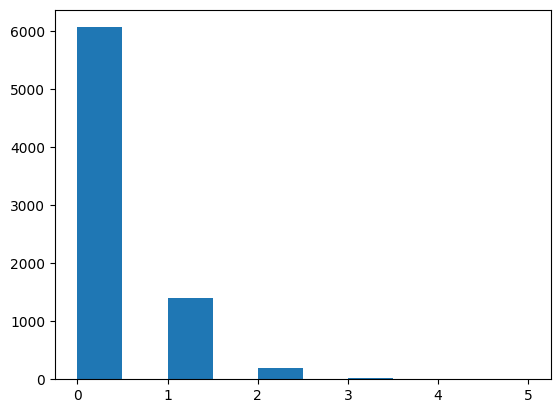

In [19]:
plt.hist(fights['f1_knockdowns'])

## Save Cleaned Data

In [20]:
fights.to_csv('../data/processed/fights_cleaned.csv', index=False)
print('Cleaned data saved to processed/flights_cleaned.csv with shape:', fights.shape)

Cleaned data saved to processed/flights_cleaned.csv with shape: (7697, 62)
